# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Vincent Valentino | 5054251016 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score,davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

In [2]:
live = pd.read_csv('Live.csv')
display(live.shape)
display(live.head())

(7050, 16)

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


In [3]:
live.info()

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)
memory usage: 1014.0

In [4]:
live.describe(include='all')

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050,7050,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
unique,NaN,4,6913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,photo,3/20/2018 1:54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4288,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,3525.500000,NaN,NaN,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,NaN,NaN,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,NaN,NaN,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,NaN,NaN,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,NaN,NaN,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN


In [5]:
live = live.drop(columns='status_id')
print(live.duplicated().sum())
display(live.isnull().sum())

54


status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

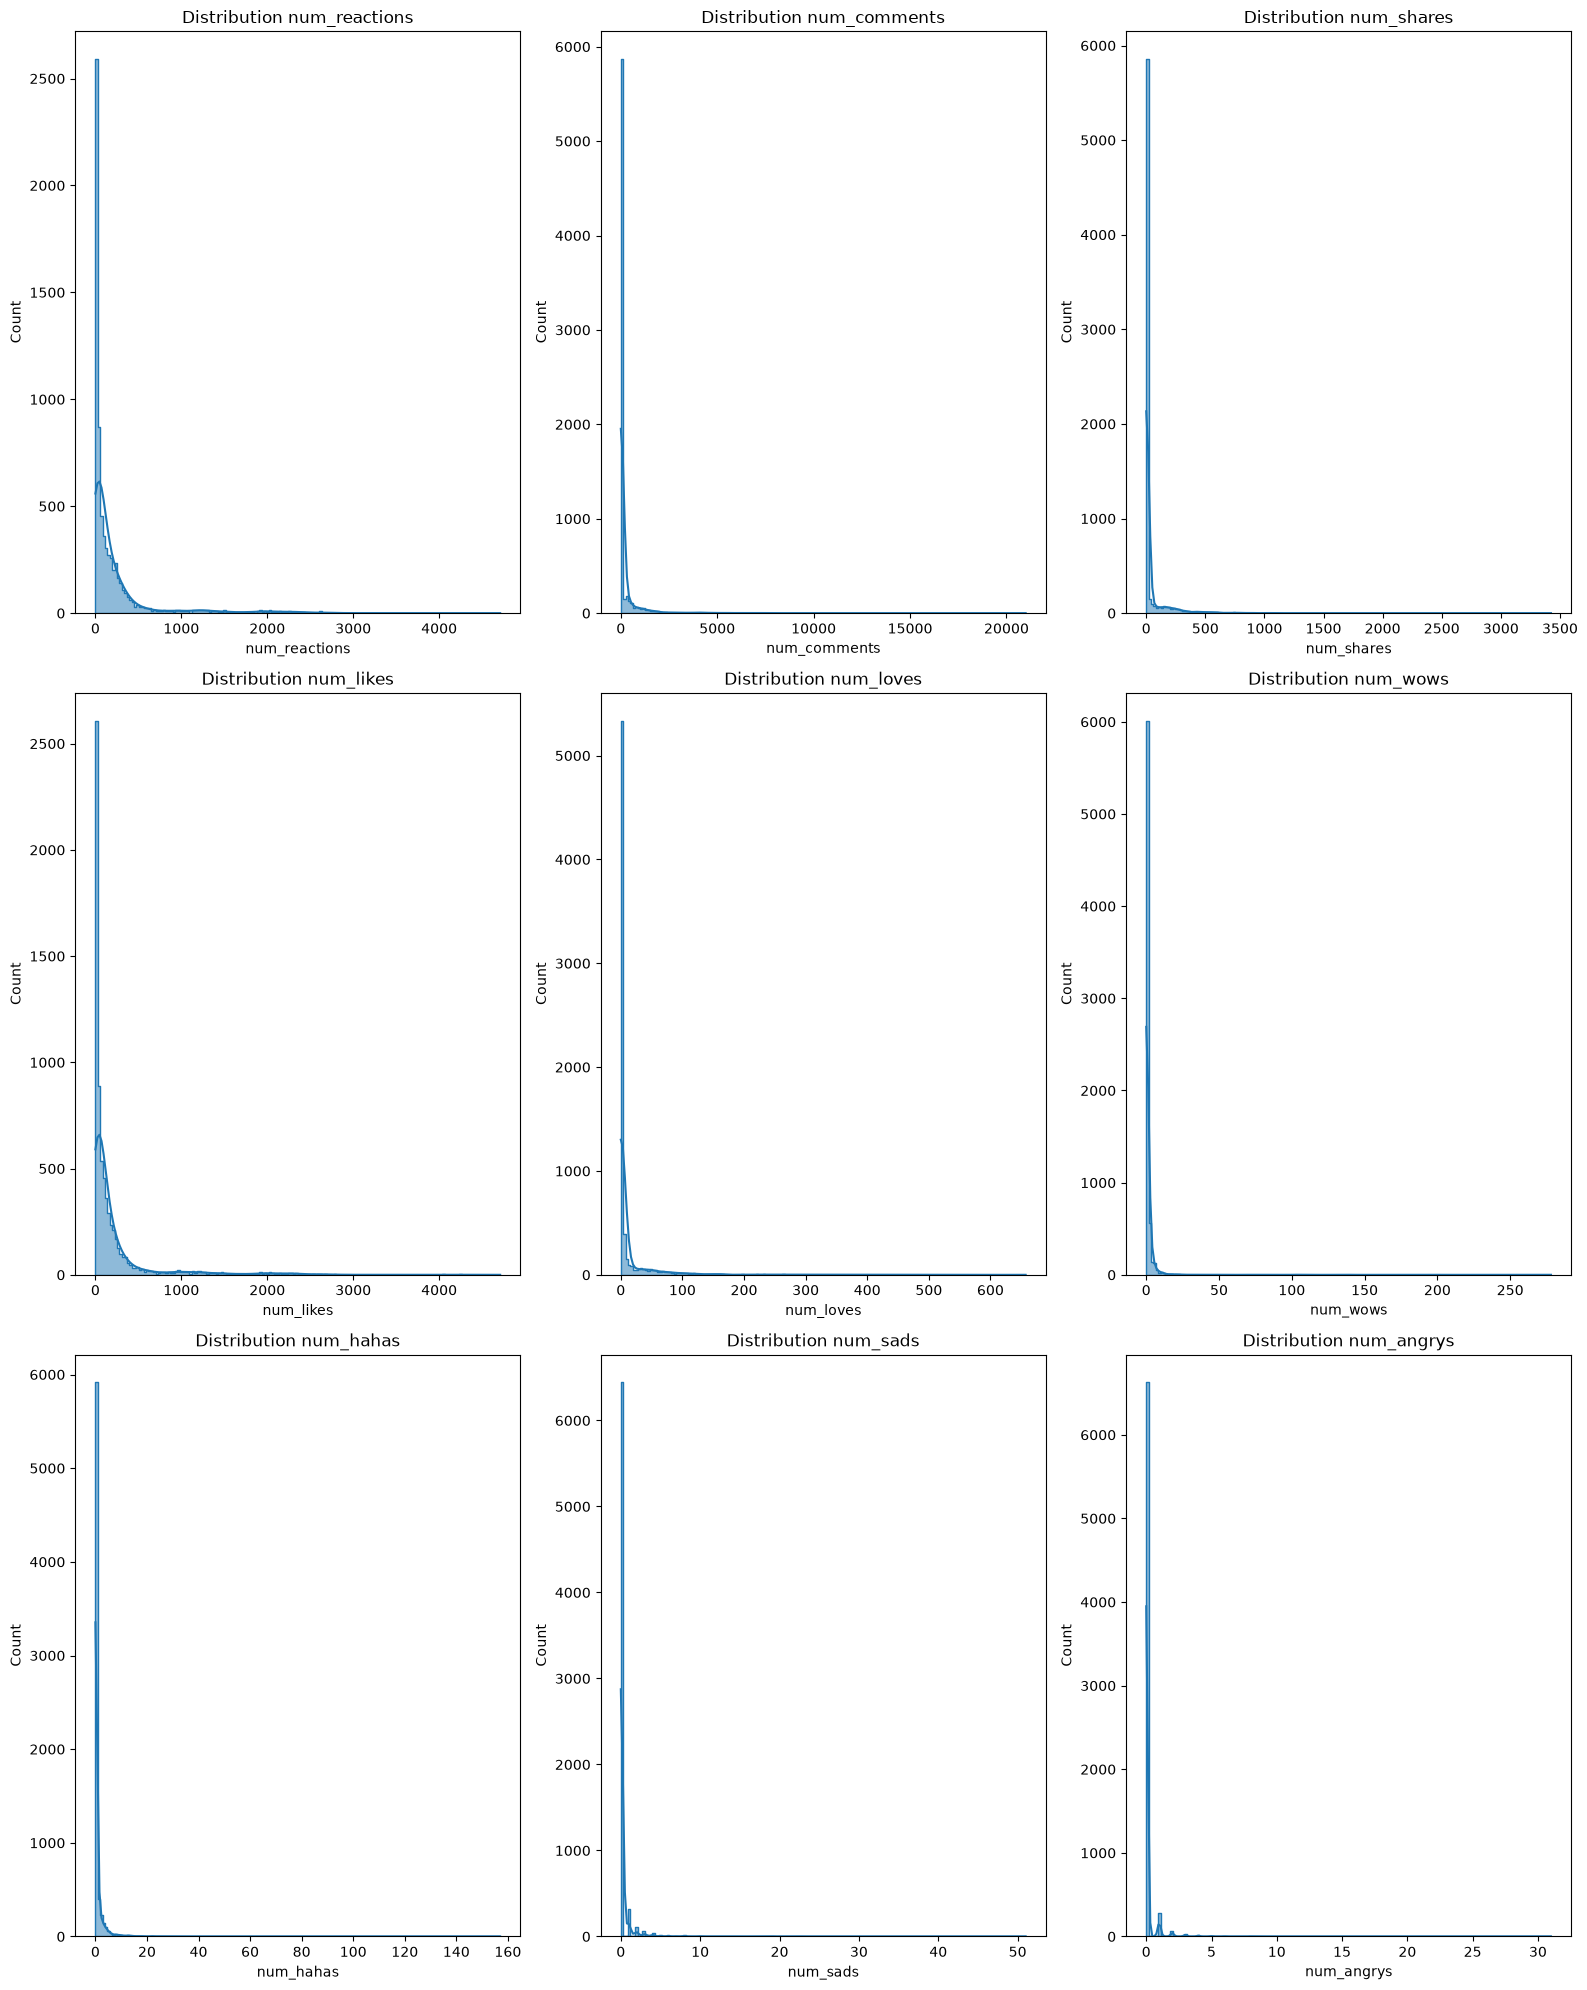

In [6]:
numerical = live.select_dtypes(include= ['int64', 'float64']).columns
fig, axes = plt.subplots(3, 3, figsize=(16, 20))
axes = axes.flatten()
for ax, col in zip(axes, numerical):
    sb.histplot(data=live, x=col, kde=True, element='step', ax=ax)
    ax.set_title(f'Distribution {col}')
    ax.set_xlabel(col)

for ax in axes[len(numerical):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

In [7]:
live.skew(numeric_only=True)

num_reactions     3.738452
num_comments      9.028850
num_shares        7.099332
num_likes         3.919128
num_loves         6.004845
num_wows         18.246813
num_hahas        20.305741
num_sads         17.578868
num_angrys       19.507129
Column1                NaN
Column2                NaN
Column3                NaN
Column4                NaN
dtype: float64

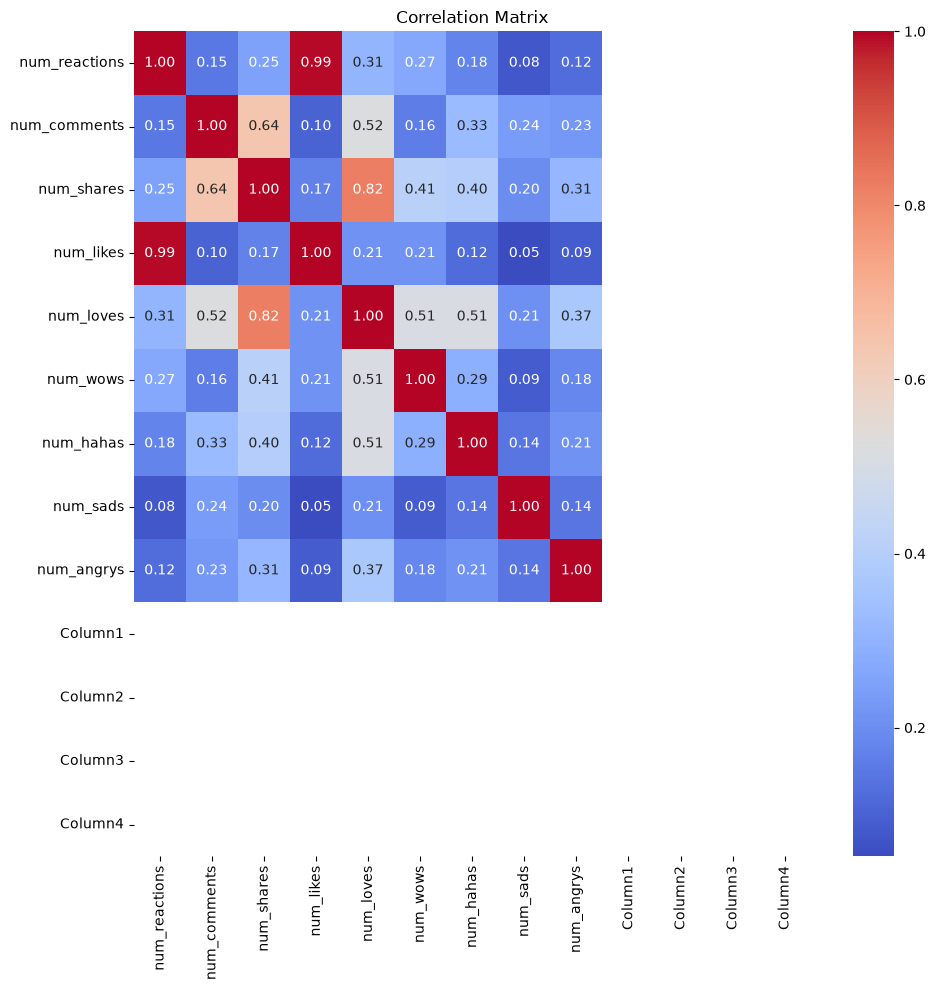

In [8]:
plt.figure(figsize=(10,10))
sb.heatmap(live[numerical].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [9]:
live['status_published'] = pd.to_datetime(live['status_published'])
live['year'] = live['status_published'].dt.year

In [10]:
emoji_columns = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
live['total_emoji'] = live[emoji_columns].sum(axis=1)
live['has_emoji'] = live['total_emoji'] > 0
hasil = live.groupby('year').agg(
    Total_Posting=('has_emoji', 'count'),
    Posting_Dengan_Emoji=('has_emoji', 'sum'),
    Proporsi_Emoji=('has_emoji', 'mean')
).reset_index()
hasil

,year,Total_Posting,Posting_Dengan_Emoji,Proporsi_Emoji
0,2012,589,0,0.000000
1,2013,500,0,0.000000
2,2014,233,0,0.000000
3,2015,337,0,0.000000
4,2016,588,400,0.680272
5,2017,2253,1221,0.541944
6,2018,2550,1473,0.577647


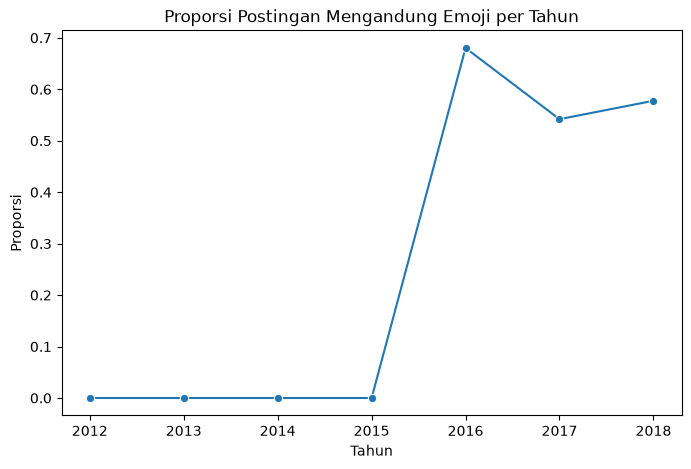

In [11]:
plt.figure(figsize=(8, 5))
sb.lineplot(data=hasil, x='year', y='Proporsi_Emoji', marker='o')
plt.title('Proporsi Postingan Mengandung Emoji per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Proporsi')
plt.show()

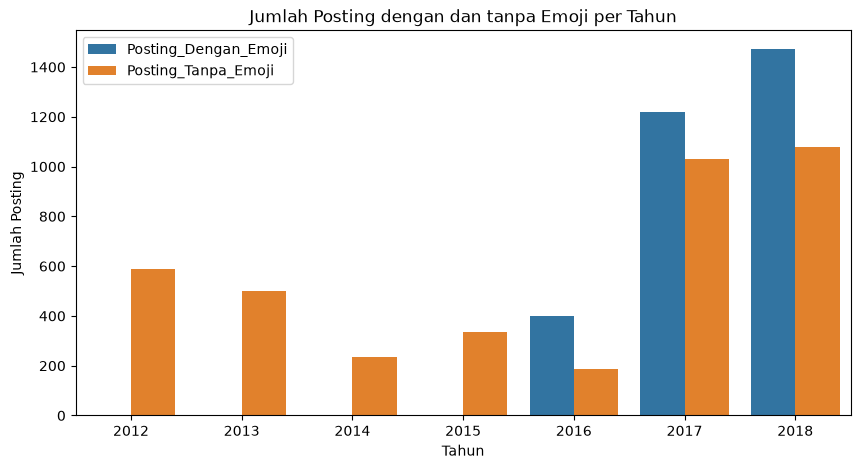

In [12]:
hasil['Posting_Tanpa_Emoji'] = (hasil['Total_Posting'] - hasil['Posting_Dengan_Emoji'])
hasil_plot = hasil.melt(id_vars='year', value_vars=['Posting_Dengan_Emoji', 'Posting_Tanpa_Emoji'], var_name='Kategori', value_name='Jumlah')
plt.figure(figsize=(10, 5))
sb.barplot(data=hasil_plot, x='year', y='Jumlah', hue='Kategori')
plt.title('Jumlah Posting dengan dan tanpa Emoji per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Jumlah Posting')
plt.legend(title='')
plt.show()


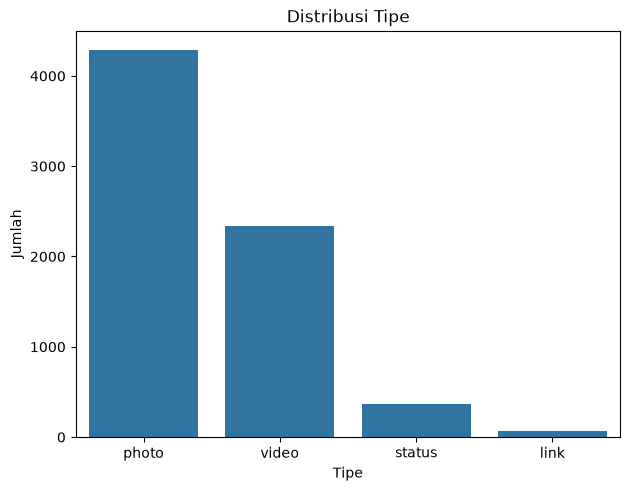

In [13]:
status = live['status_type'].value_counts()
sb.barplot(data=status)
plt.tight_layout()
plt.title('Distribusi Tipe')
plt.xlabel('Tipe')
plt.ylabel('Jumlah')
plt.show()

In [14]:
median_engagement = live.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()
display(median_engagement)

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [15]:
live = live.drop_duplicates()
live = live.drop(columns=['Column1', 'Column2', 'Column3', 'Column4'])

Berdasarkan korelasi matrix, `num_reactions` dan `num_likes` memiliki korelasi 0,99 menandakan adanya redundansi, maka `num_reactions` didrop.

In [16]:
live = live.drop(columns=['num_reactions'])

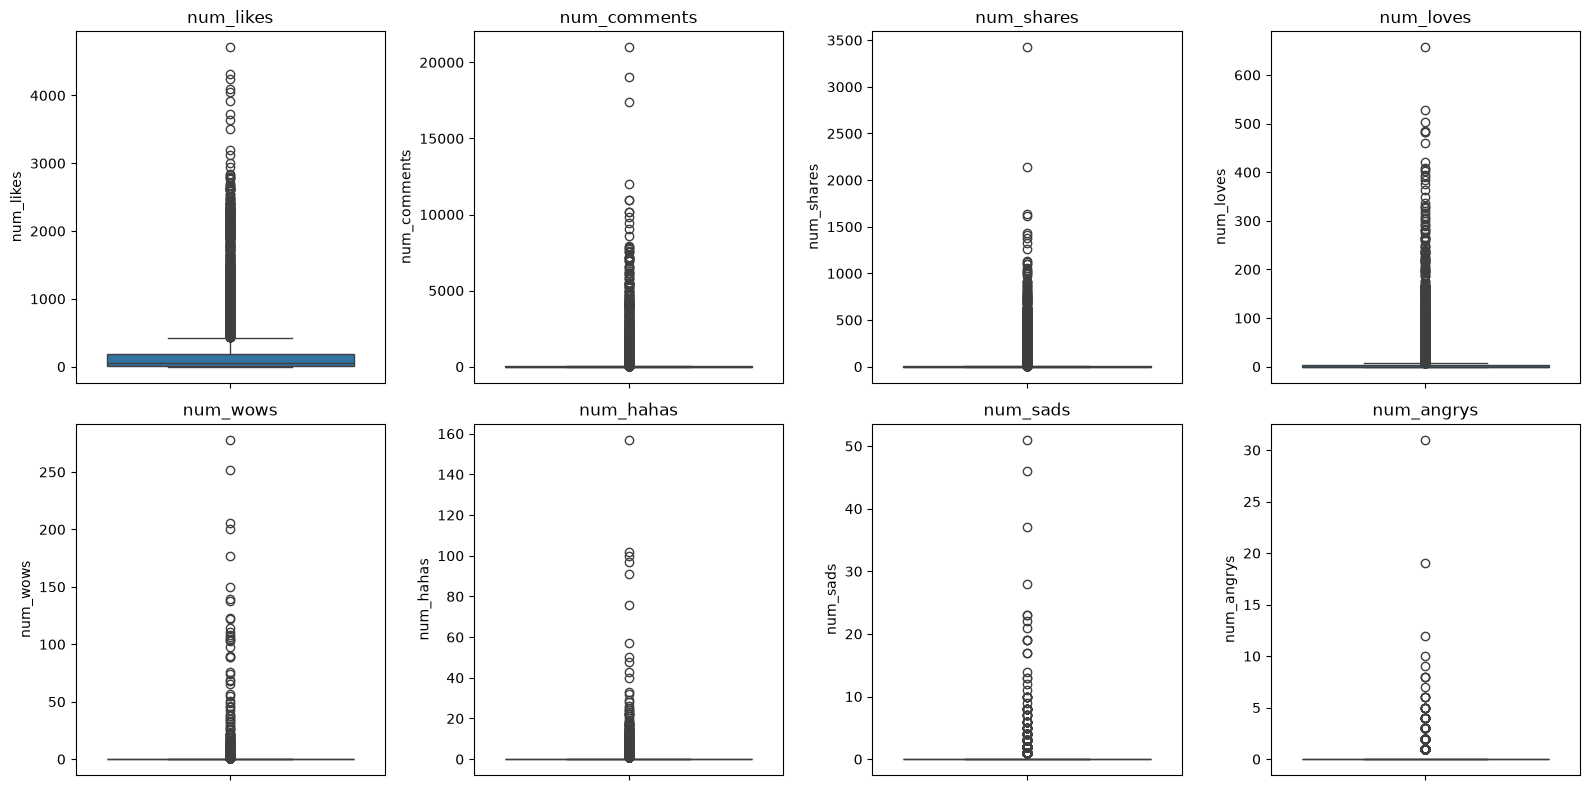

In [17]:
engagement_cols = [
    'num_likes',
    'num_comments',
    'num_shares',
    'num_loves',
    'num_wows',
    'num_hahas',
    'num_sads',
    'num_angrys'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, engagement_cols):
    sb.boxplot(data=live, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [18]:
outlier_results = []

for col in engagement_cols:
    Q1 = live[col].quantile(0.25)
    Q3 = live[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    extreme_outliers = live[
        (live[col] < Q1 - 3 * IQR) |
        (live[col] > Q3 + 3 * IQR)
    ]

    outlier_results.append({
        'Feature': col,
        'Extreme Outlier Count': len(extreme_outliers),
        'Extreme Outlier Percentage': (len(extreme_outliers) / len(live))*100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Extreme Outlier Count,Extreme Outlier Percentage
0,num_likes,540,7.72
1,num_comments,1245,17.80
2,num_shares,1237,17.68
3,num_loves,1126,16.09
4,num_wows,1702,24.33
5,num_hahas,1117,15.97
6,num_sads,598,8.55
7,num_angrys,420,6.00


In [19]:
distribution = pd.DataFrame({
    'Zero Count': (live[engagement_cols] == 0).sum(),
    'Q1': live[engagement_cols].quantile(0.25),
    'Median': live[engagement_cols].median(),
    'Q3': live[engagement_cols].quantile(0.75),
    'IQR': (
        live[engagement_cols].quantile(0.75) -
        live[engagement_cols].quantile(0.25)
    )
})

display(distribution.round(2))

,Zero Count,Q1,Median,Q3,IQR
num_likes,123,17.0,57.0,182.00,165.00
num_comments,2116,0.0,4.0,22.25,22.25
num_shares,3905,0.0,0.0,4.00,4.00
num_loves,4225,0.0,0.0,3.00,3.00
num_wows,5294,0.0,0.0,0.00,0.00
num_hahas,5879,0.0,0.0,0.00,0.00
num_sads,6398,0.0,0.0,0.00,0.00
num_angrys,6576,0.0,0.0,0.00,0.00


Tingginya jumlah outlier pada fitur `num_wows`, `num_hahas`, `num_sads`, dan `num_angrys` disebabkan oleh tingginya proporsi nilai nol pada fitur-fitur tersebut. Oleh karena itu, nilai tersebut tetap dipertahankan tanpa dilakukan perubahan.

In [20]:
df_metadata = live[['status_type', 'status_published']].copy()

df_cluster = live[['num_likes', 'num_comments', 'num_shares','total_emoji']].copy()

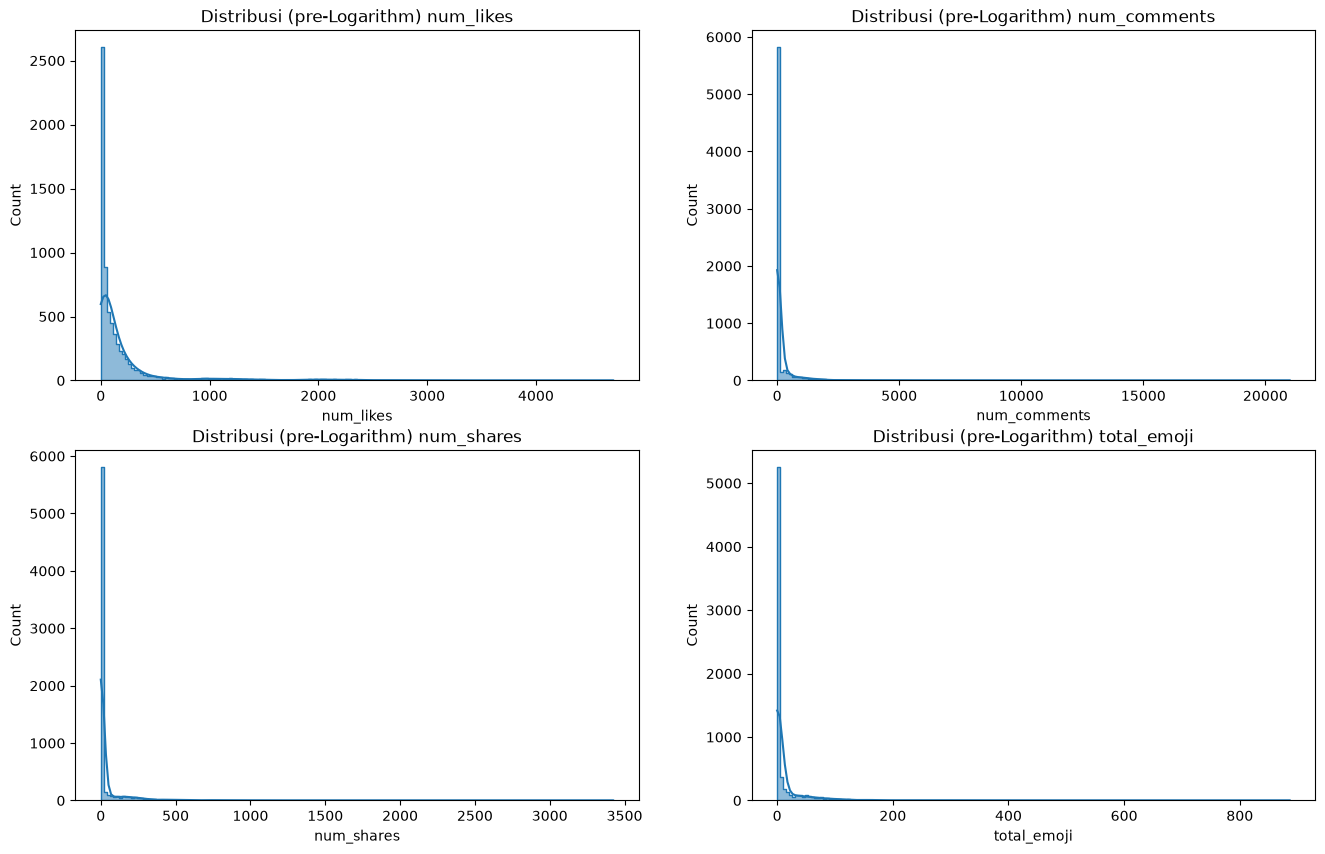

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
for ax, col in zip(axes, df_cluster.columns):
    sb.histplot(data=df_cluster, x=col, kde=True, element='step', ax=ax)
    ax.set_title(f'Distribusi (pre-Logarithm) {col}')
    ax.set_xlabel(col)

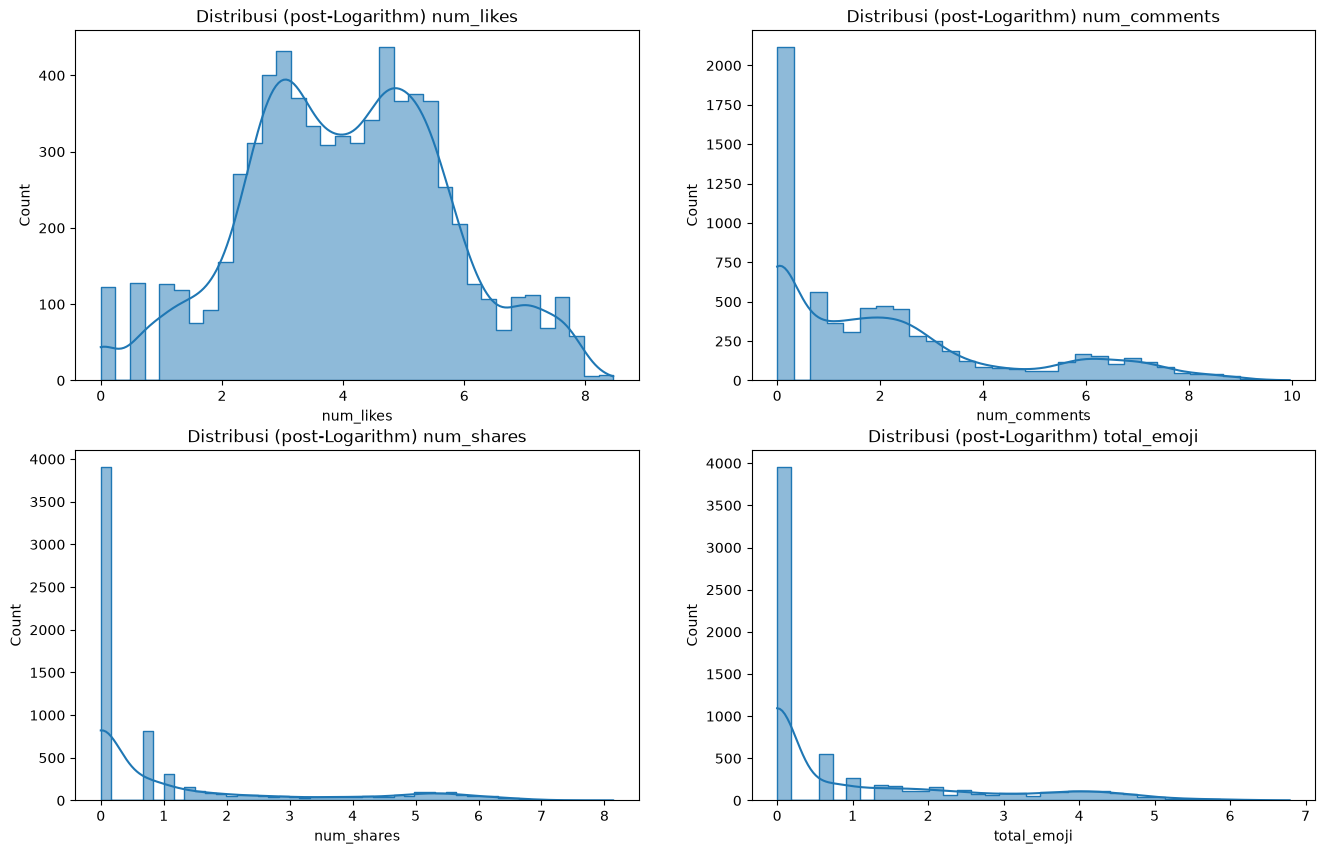

In [22]:
log_cluster = np.log1p(df_cluster)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
for ax, col in zip(axes, log_cluster.columns):
    sb.histplot(data=log_cluster, x=col, kde=True, element='step', ax=ax)
    ax.set_title(f'Distribusi (post-Logarithm) {col}')
    ax.set_xlabel(col)

**Fitur yang dipilih untuk clustering:** `num_likes` karena merepresentasikan jumlah likes, `num_shares` karena merepresentasikan penyebaran posting, `num_comments` karena merepresentasikan interaksi melalui komentar, `total_emoji` karena merepresentasikan total reaksi emoji

In [23]:
scaler = StandardScaler()
x_log = log_cluster.copy()
x_log_scaled = scaler.fit_transform(x_log)
x_raw = df_cluster.copy()
x_raw_scaled = scaler.fit_transform(x_raw)

# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [24]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_raw = kmeans.fit_predict(x_raw)
labels_raw_scaled = kmeans.fit_predict(x_raw_scaled)
labels_log_scaled = kmeans.fit_predict(x_log_scaled)

In [25]:
cluster_results = pd.DataFrame({
    'Raw': labels_raw,
    'Raw Scaled': labels_raw_scaled,
    'Log Scaled': labels_log_scaled
}, index=x_raw.index)

cluster_counts = pd.DataFrame({
    col: cluster_results[col].value_counts().sort_index() for col in cluster_results.columns
})

cluster_counts

,Raw,Raw Scaled,Log Scaled
0,338,5900,1725
1,6217,110,1101
2,58,613,1753
3,383,373,2417


In [26]:
silhouette_results = pd.DataFrame({
    'Dataset': ['Raw', 'Raw Scaled', 'Log Scaled'],
    'Silhouette Score': [
        silhouette_score(x_log_scaled, labels_raw),
        silhouette_score(x_log_scaled, labels_raw_scaled),
        silhouette_score(x_log_scaled, labels_log_scaled)
    ]
})

print(silhouette_results)

      Dataset  Silhouette Score
0         Raw          0.236512
1  Raw Scaled          0.326035
2  Log Scaled          0.337208


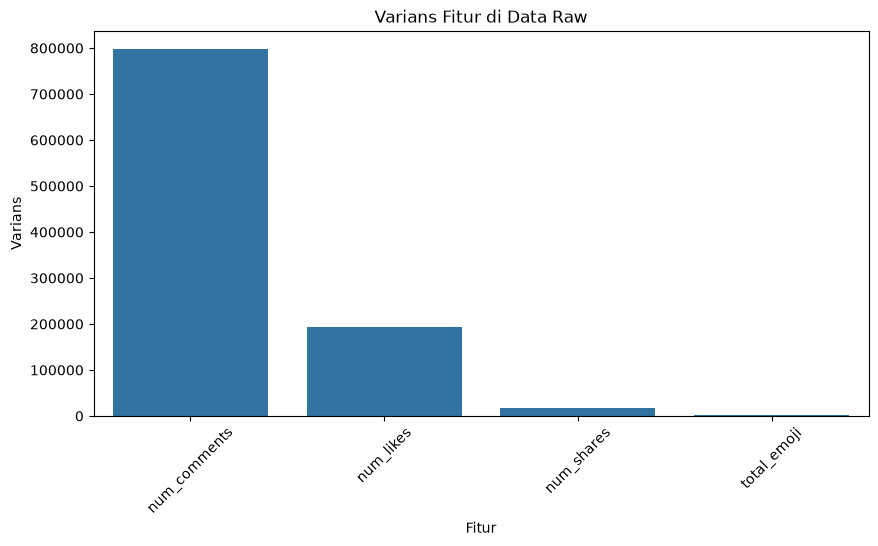

In [27]:
raw_variance = x_raw.var().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sb.barplot(x=raw_variance.index, y=raw_variance.values)
plt.title('Varians Fitur di Data Raw')
plt.xlabel('Fitur')
plt.ylabel('Varians')
plt.xticks(rotation=45)
plt.show()

## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [28]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x_log_scaled)
    inertias.append(kmeans.inertia_)

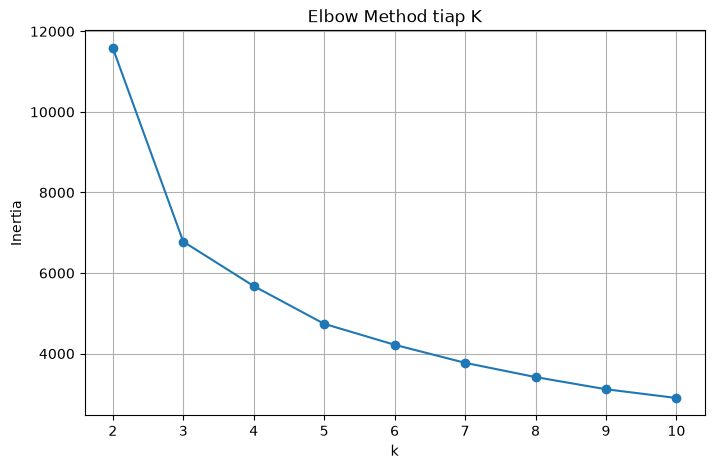

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')
plt.title('Elbow Method tiap K')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid()
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [30]:
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(x_log_scaled)
    score = silhouette_score(x_log_scaled, labels)
    silhouette_scores.append(score)

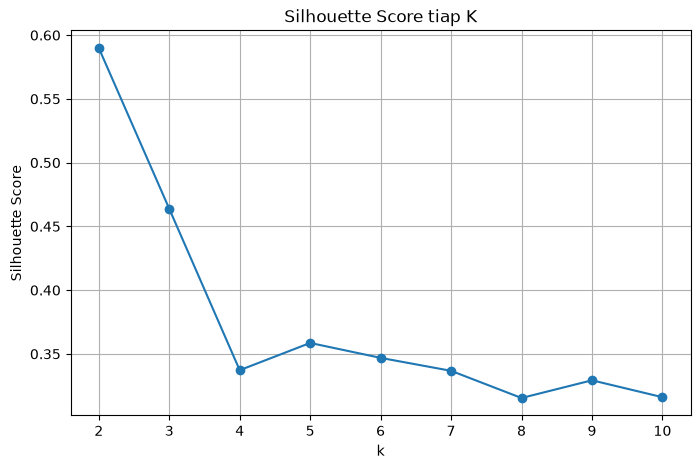

In [31]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.title('Silhouette Score tiap K')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.grid()
plt.show()

**Pilihan k untuk K-Means:** 5 karena trade-off yang cukup seimbang antar kualitas kluster dan reduksi inertia.

## 3.4 Model K-Means Final

In [32]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
label = kmeans.fit_predict(x_log_scaled)

In [33]:
clustered_data = df_cluster.copy()
clustered_data['cluster'] = label

clustered_data.head()

,num_likes,num_comments,num_shares,total_emoji,cluster
0,432,512,262,97,2
1,150,0,0,0,3
2,204,236,57,23,2
3,111,0,0,0,3
4,204,0,0,9,4


In [34]:
cluster_size = clustered_data['cluster'].value_counts().sort_index()
cluster_median = clustered_data.groupby('cluster').median()
cluster_mean = clustered_data.groupby('cluster').mean()
display(cluster_size)
display(cluster_median)
display(cluster_mean)

cluster
0     651
1    1731
2    1076
3    2393
4    1145
Name: count, dtype: int64

,num_likes,num_comments,num_shares,total_emoji
cluster,,,,
0,906.0,13.0,1.0,0.0
1,8.0,0.0,0.0,0.0
2,168.0,783.0,187.0,59.0
3,37.0,2.0,0.0,0.0
4,195.0,14.0,1.0,6.0


,num_likes,num_comments,num_shares,total_emoji
cluster,,,,
0,1080.688172,29.279570,6.932412,0.049155
1,8.299249,0.414789,0.291161,0.099942
2,292.631970,1392.738848,249.315985,86.382900
3,48.844964,4.767656,1.045132,0.474300
4,279.270742,42.675983,5.229694,9.618341


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [44]:
Z = linkage(x_log_scaled, method='ward')

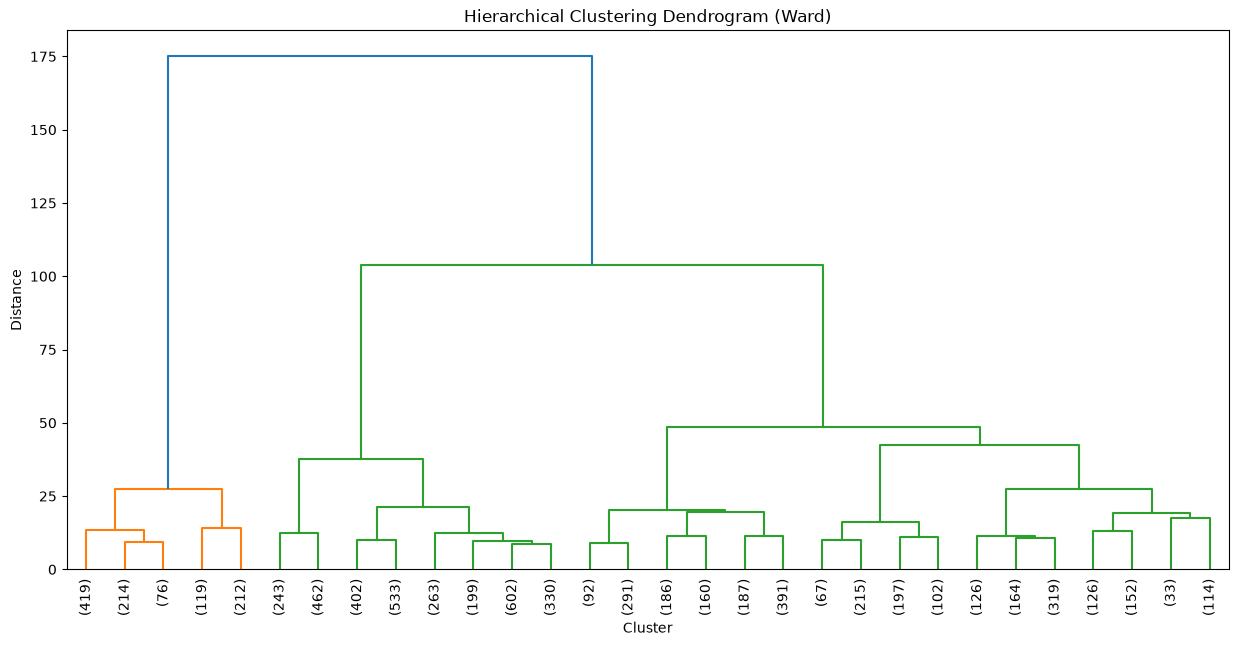

In [45]:
plt.figure(figsize=(15, 7))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram (Ward)')
plt.xlabel('Cluster')
plt.ylabel('Distance')
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [47]:
linkages = ['ward', 'complete', 'average', 'single']
hierarchical_results = {}
comparison_data = []

for method in linkages:
    model = AgglomerativeClustering(n_clusters=2, linkage=method)
    labels = model.fit_predict(x_log_scaled)
    silhouette = silhouette_score(x_log_scaled, labels)
    cluster_counts = pd.Series(labels).value_counts().sort_index()
    hierarchical_results[method] = labels
    row = {
        'Linkage': method,
        'Silhouette Score': silhouette
    }
    for cluster_id, count in cluster_counts.items():
        row[cluster_id] = count
    comparison_data.append(row)

comparison_table = pd.DataFrame(comparison_data).set_index('Linkage')
comparison_table

,Silhouette Score,0,1
Linkage,,,
ward,0.595095,5956,1040
complete,0.505746,6536,460
average,0.592165,1232,5764
single,0.387694,6995,1


**Pilihan linkage untuk Hierarchical Clustering:** Ward, karena memiliki Silhouette Score yang tertinggi

## 4.3 Model Hierarchical Clustering Final

In [ ]:
hc = AgglomerativeClustering(n_clusters=5, linkage='ward')
hc_labels = hc.fit_predict(x_log_scaled)
hc_cluster_size = pd.Series(hc_labels).value_counts().sort_index()
display(hc_cluster_size)

0    3034
1    1040
2    1034
3    1307
4     581

In [ ]:
clustered_data_hc = df_cluster.copy()
clustered_data_hc['cluster'] = hc_labels

hc_cluster_size = clustered_data_hc['cluster'].value_counts().sort_index()
hc_cluster_median = clustered_data_hc.groupby('cluster').median()
hc_cluster_mean = clustered_data_hc.groupby('cluster').mean()

display(hc_cluster_size)
display(hc_cluster_median)
display(hc_cluster_mean)

,count
cluster,
0,3034
1,1040
2,1034
3,1307
4,581


,num_likes,num_comments,num_shares,total_emoji
cluster,,,,
0,14.0,0.0,0.0,0.0
1,168.0,815.5,193.5,60.5
2,227.0,18.0,2.0,7.0
3,70.0,3.0,0.0,1.0
4,924.0,12.0,1.0,0.0


,num_likes,num_comments,num_shares,total_emoji
cluster,,,,
0,16.707317,1.755438,0.245880,0.148649
1,277.532692,1430.190385,255.400962,88.238462
2,376.707930,64.068665,10.691489,10.838491
3,88.716909,7.576129,1.915838,1.433053
4,1075.084337,16.808950,3.180723,0.003442


# 5. Evaluasi Model

In [ ]:
kmeans_labels = label

comparison_metrics = pd.DataFrame({
    'K-Means': [
        silhouette_score(x_log_scaled, kmeans_labels),
        davies_bouldin_score(x_log_scaled, kmeans_labels),
        calinski_harabasz_score(x_log_scaled, kmeans_labels)
    ],
    'Hierarchical Clustering (Ward)': [
        silhouette_score(x_log_scaled, hc_labels),
        davies_bouldin_score(x_log_scaled, hc_labels),
        calinski_harabasz_score(x_log_scaled, hc_labels)
    ]
}, index=[
    'Silhouette Score (↑)',
    'Davies-Bouldin Index (↓)',
    'Calinski-Harabasz Score (↑)'
])

display(comparison_metrics)

,K-Means,Hierarchical Clustering (Ward)
Silhouette Score (↑),0.358574,0.346536
Davies-Bouldin Index (↓),1.016982,1.119287
Calinski-Harabasz Score (↑),8570.740137,7648.874023


In [ ]:
pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(x_log_scaled)
var_exp = pca.explained_variance_ratio_

print("Persentase Varians yang Dijelaskan:")
print(f"PC1: {var_exp[0]*100}%")
print(f"PC2: {var_exp[1]*100}%")
print(f"Total Varians: {sum(var_exp)*100}%")

cluster_labels = [kmeans_labels, hc_labels]
titles = ['K-Means Clustering (k=5)', 'Hierarchical Clustering (Ward, k=5)']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes = axes.flatten()

for ax, labels, title in zip(axes, cluster_labels, titles):
    sb.scatterplot(x=x_pca[:, 0], y=x_pca[:, 1], alpha=0.6, ax=ax)
    ax.set_title(f'{title} Explained Variance: {sum(var_exp)*100}%')
    ax.set_xlabel(f'Principal Component 1 ({var_exp[0]*100}%)')
    ax.set_ylabel(f'Principal Component 2 ({var_exp[1]*100}%)')
    ax.legend(title='Cluster')

plt.tight_layout()
plt.show()

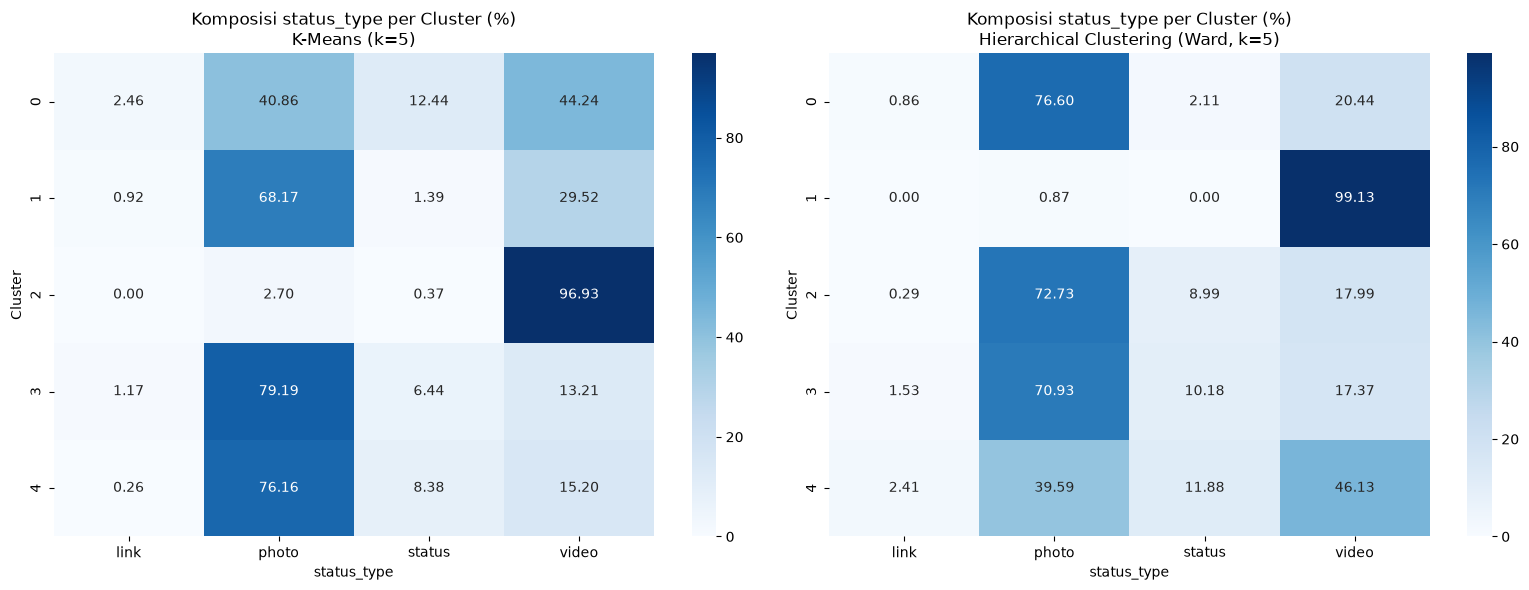

In [ ]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
crosstab_kmeans = pd.crosstab(kmeans_labels, df_metadata['status_type'], normalize='index')*100
crosstab_hc = pd.crosstab(hc_labels, df_metadata['status_type'], normalize='index'
) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sb.heatmap(crosstab_kmeans, annot=True, fmt='.2f', cmap='Blues', ax=axes[0])
axes[0].set_title('Komposisi status_type per Cluster (%)
K-Means (k=5)')
axes[0].set_xlabel('status_type')
axes[0].set_ylabel('Cluster')

sb.heatmap(crosstab_hc, annot=True, fmt='.2f', cmap='Blues', ax=axes[1])
axes[1].set_title('Komposisi status_type per Cluster (%)
Hierarchical Clustering (Ward, k=5)')
axes[1].set_xlabel('status_type')
axes[1].set_ylabel('Cluster')

plt.tight_layout()
plt.show()

# 6. Analisis

### 1. Pengaruh Transformasi Log dan Feature Scaling pada K-Means
Berdasarkan hasil eksperimen pada bagian 3.1 dengan jumlah cluster (k=4), terlihat bahwa transformasi log dan feature scaling memberikan pengaruh terhadap hasil pengelompokan data.
- **Data Raw:** Hasil clustering menunjukkan distribusi yang sangat tidak seimbang. Dari 6.999 data, sebanyak 6.217 sampel (88,8%) terkumpul dalam satu cluster, sedangkan tiga cluster lainnya masing-masing hanya berisi 383, 338, dan 58 sampel. Kondisi ini juga menghasilkan Silhouette Score terendah, yaitu **0,2365**.
- **Data Raw Scaled:** Scaling meningkatkan Silhouette Score menjadi **0,3260**. Namun, distribusi cluster masih belum merata karena 5.900 sampel masih terkumpul dalam satu cluster.
- **Data Log Scaled:** Kombinasi transformasi log dan scaling menghasilkan distribusi cluster yang lebih seimbang, dengan jumlah anggota masing-masing 2.417, 1.753, 1.725, dan 1.101 sampel. Hasil ini juga memperoleh Silhouette Score tertinggi, yaitu **0,3372**.
Hasil tersebut menunjukkan bahwa penggunaan transformasi log dan feature scaling secara bersamaan memberikan hasil clustering yang lebih baik dibandingkan kedua pendekatan lainnya.

**Mengapa transformasi log dan feature scaling penting pada algoritma berbasis jarak?**
K-Means menggunakan jarak Euclidean untuk menentukan kedekatan antar data. Oleh karena itu, perbedaan skala dan distribusi fitur dapat memengaruhi proses pembentukan cluster.
1. **Perbedaan Skala Variansi:** Fitur dengan rentang nilai dan variansi yang lebih besar dapat mendominasi perhitungan jarak Euclidean. Akibatnya, kontribusi fitur dengan skala lebih kecil menjadi kurang signifikan. Scaling membantu menyetarakan skala antarfitur sehingga setiap fitur dapat memberikan kontribusi yang lebih proporsional.
2. **Skewed Distribution:** Sejumlah kecil observasi dengan nilai ekstrem dapat memberikan kontribusi yang jauh lebih besar terhadap jarak dibandingkan observasi lainnya. Pada algoritma K-Means, kondisi ini dapat memengaruhi penentuan centroid dan pembentukan cluster sehingga pengelompokan lebih didominasi oleh perbedaan nilai ekstrem.

#### 2. Penanganan Kolom Redundan dan Fitur Bernilai Nol
* **Penanganan Fitur Redundan**: Kolom `num_reactions` dihapus karena memiliki korelasi linear sebesar **0,99** dengan `num_likes`.
* **Penanganan Kolom Berisi Banyak Nilai Nol (Emoji)**: Fitur reaksi individual (`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`) didominasi oleh nilai 0 (>80-90% data bernilai 0). Jika masing-masing dimasukkan terpisah, matriks jarak akan didominasi oleh 0. Solusi yang diambil adalah menggabungkannya ke dalam satu fitur representatif: `total_emoji`
* **Fitur yang Dipilih untuk Clustering**:
  Dipilih 4 fitur numerik utama:
  1. `num_likes`: Representasi apresiasi langsung / reaksi dasar audiens.
  2. `num_comments`: Representasi interaksi dua arah dan percakapan.
  3. `num_shares`: Representasi viralitas dan distribusi konten secara organik.
  4. `total_emoji`: Representasi ekspresi emosional pengguna secara keseluruhan.

#### 3. Jumlah Cluster Optimal: Elbow Method vs. Silhouette Score
* **Elbow Method (Inertia/WCSS)**:
  Penurunan inertia turun drastis dari k=2 ke k=3, lalu mulai melandai pada k=4 dan k=5. Siku secara visual terbentuk di area k=3 hingga k=5.
* **Silhouette Score**:
  Nilai Silhouette tertinggi dari grafik terdapat pada k=2 (0,5899), diikuti k=3 (0,4638). Namun pada rentang $k \ge 4$, nilai Silhouette mengalami local peak pada k=5 (0,3586).
* **Perbandingan Kesimpulan dan Pemilihan Nilai k**:
  Keduanya tidak memberikan angka tunggal yang persis sama, kecuali k=2. Namun jika memilih k=2, data hanya terbelah menjadi kelompok biner (postingan sangat sepi vs postingan ada interaksi), yang kurang memberikan wawasan bisnis yang tajam bagi penjual online.
  Oleh karena itu, dipilih **k = 5**. Pilihan ini merupakan *sweet spot* karena:
  1. Berada pada area di mana penurunan inertia sudah melandai (Elbow Method).
  2. Merupakan puncak lokal Silhouette Score untuk pengelompokan yang lebih detail ($k \ge 4$).

#### 4. Perbandingan Metode Linkage pada Hierarchical Clustering
Pada eksperimen perbandingan linkage (k=2):
* **Ward Linkage**: Menghasilkan Silhouette Score tertinggi (0,5951) dan pembagian cluster yang seimbang (5.956 dan 1.040 sampel).
* **Complete Linkage**: Menghasilkan Silhouette Score **0,5057** dengan distribusi 6.536 dan 460 sampel.
* **Average Linkage**: Menghasilkan Silhouette Score **0,5922** dengan distribusi 5.764 dan 1.232 sampel. Cukup baik karena mempertimbangkan rata-rata seluruh pasangan titik.
* **Single Linkage**: Menghasilkan Silhouette Score terendah (**0,3877**) dan distribusi yang sangat cacat yaitu 6.995 sampel di Cluster 0 dan hanya 1 sampel di Cluster 1.
  * **Karakteristik Single Linkage**: Menggunakan jarak minimum antar pasangan titik terdekat, sehingga sangat rentan terhadap **Chaining Effect** (efek berantai). Cluster akan terus "menjalar" menghubungkan titik-titik yang berdekatan satu per satu, sehingga seluruh kumpulan data melebur menjadi satu komponen raksasa dan hanya memisahkan 1 titik outlier terjauh sebagai cluster tersendiri.
Jadi, Ward adalah metode linkage terbaik karena menghasilkan cluster yang kompak, ukuran cluster yang wajar/seimbang, dan skor pemisahan tertinggi.

#### 5. Performa K-Means vs. Hierarchical Clustering (Ward)
Berdasarkan evaluasi internal pada $k=5$:
* **Metrik Evaluasi Internal**:
  * **Silhouette Score**: K-Means (**0,3586**) sedikit lebih unggul dibanding HC Ward (**0,3465**).
  * **Davies-Bouldin Index**: K-Means (**1,0170**) lebih baik dibanding HC Ward (**1,1193**).
  * **Calinski-Harabasz Score**: K-Means (**8570,74**) lebih unggul secara signifikan dibanding HC Ward (**7648,87**).
* **Visualisasi PCA 2D**:
  Dua komponen utama PCA mampu menjelaskan **91,82% total varians** data (PC1 = 75,87%, PC2 = 15,95%). Scatter plot 2D menunjukkan bahwa partisi spasial yang dihasilkan oleh K-Means dan Hierarchical Clustering (Ward) sangat mirip dan memiliki batas-batas cluster yang konsisten.
* **Mengapa hasilnya tidak berbeda signifikan dan K-Means sedikit lebih unggul?**
  1. Ward Linkage pada Hierarchical Clustering dan K-Means sama-sama bekerja untuk meminimalkan jumlah kuadrat deviasi (varians error / SSE) di dalam cluster.
  2. K-Means unggul tipis karena bersifat optimasi iteratif partisional global, yang dimana titik data dapat berpindah cluster kapan saja seiring pergeseran centroid hingga optimal. Sebaliknya, Agglomerative HC bersifat greedy deterministik, yang dimana dua titik/cluster yang telah digabungkan di awal tidak dapat dipisahkan kembali pada tahapan berikutnya, sehingga sedikit membatasi fleksibilitas.

#### 6. Karakteristik dan Profil Tiap Cluster (K-Means k=5)
Berdasarkan profil median fitur engagement asli dan komposisi `status_type`:

1. **Cluster 0 (N = 651 | Aesthetic)**:
   * Profil Median: `num_likes`: 906, `num_comments`: 13, `num_shares`: 1, `total_emoji`: 0.
   * Komposisi: Video (44,24%), Photo (40,86%), Status (12,44%), Link (2,46%).
   * Karakteristik: Postingan yang menarik impresi visual tinggi sehingga disukai ratusan hingga ribuan audiens, tetapi interaksi diskusinya (komentar dan share) tergolong pasif.

2. **Cluster 1 (N = 1.731 | Low-Engagement)**:
   * Profil Median: `num_likes`: 8, `num_comments`: 0, `num_shares`: 0, `total_emoji`: 0.
   * Komposisi: Photo (68,17%), Video (29,52%), Status (1,39%), Link (0,92%).
   * Karakteristik: Postingan dengan engagement sangat rendah atau sepi.

3. **Cluster 2 (N = 1.076 | High Interactive Selling)**:
   * Profil Median: `num_likes`: 168, `num_comments`: 783, `num_shares`: 187, `total_emoji`: 59.
   * Komposisi: Video (96,93%), Photo (2,70%), Status (0,37%).
   * Karakteristik: Segmen paling aktif dan interaktif, didominasi hampir 97% oleh video live. Jumlah komentar dan share mencapai ratusan serta emoji mencapai puluhan, menunjukkan keterlibatan langsung penonton saat live broadcast berlangsung (tanya jawab harga, tawar-menawar, dan pemesanan).

4. **Cluster 3 (N = 2.393 | Catalog)**:
   * Profil Median: `num_likes`: 37, `num_comments`: 2, `num_shares`: 0, `total_emoji`: 0.
   * Komposisi: Photo (79,19%), Video (13,21%), Status (6,44%), Link (1,17%).
   * Karakteristik: Proporsi postingan terbesar di dataset. Kemungkinan berupa foto katalog produk rutin

5. **Cluster 4 (N = 1.145 | Photo-Based Engagement Posts)**:
   * Profil Median: `num_likes`: 195, `num_comments`: 14, `num_shares`: 1, `total_emoji`: 6.
   * Komposisi: Photo (76,16%), Video (15,20%), Status (8,38%), Link (0,26%).
   * Karakteristik: Postingan foto produk/promosi yang sukses memancing engagement moderat-tinggi.

#### 7. Kelebihan dan Kekurangan: K-Means vs. Hierarchical Clustering

| Aspek | K-Means | Hierarchical Clustering (Agglomerative) |
|-|-|-|
| **Penentuan Jumlah Cluster (k)** | Harus menentukan k di awal (bisa juga melalui teknik eksplorasi (Elbow/Silhouette)). | Tidak perlu menentukan k di awal. Pengelompokan direpresentasikan dalam dendrogram dan pemotongan pohon dapat dilakukan pada ketinggian mana pun. |
| **Bentuk & Asumsi Cluster** | Mengasumsikan cluster berbentuk bulat dan berukuran seimbang karena berbasis jarak Euclidean ke centroid. | Lebih fleksibel bergantung pada linkage |
| **Kompleksitas Waktu** | Sangat cepat dan efisien | Berat secara komputasi |
| **Kebutuhan Memori** | Sangat hemat. | Sangat boros memori, rentan Out-of-Memory pada dataset besar. |
| **Sensitivitas Inisialisasi & Outlier** | Sensitif terhadap inisialisasi awal centroid (bisa terjebak di local minima, membutuhkan `n_init`) dan sensitif terhadap outlier. | Deterministik (menghasilkan struktur pohon yang selalu sama untuk data yang sama tanpa inisialisasi acak), namun keputusan penggabungan bersifat permanen. |



# 7. Kesimpulan dan Saran

### Kesimpulan
1. Kombinasi transformasi `log1p` dan `StandardScaler` menghasilkan clustering yang lebih seimbang dan meningkatkan kualitas pengelompokan dengan mengurangi pengaruh distribusi *right-skewed* dan nilai ekstrem.
2. Berdasarkan Elbow Method dan Silhouette Score, k=5 dipilih karena memberikan keseimbangan antara kualitas clustering dan kebermaknaan segmentasi.
3. Konten video, khususnya Live Streaming, mendominasi cluster dengan engagement tertinggi, sedangkan konten foto lebih banyak ditemukan pada cluster dengan engagement rendah hingga moderat.
4. K-Means dan Hierarchical Clustering dengan Ward Linkage menghasilkan pola pengelompokan yang relatif serupa. K-Means unggul dalam metrik evaluasi walaupun hanya kecil perbedaannya.

### Saran untuk Eksperimen Selanjutnya
1. **Segmentasi Temporal:** Memisahkan data sebelum dan sesudah 2016 karena fitur reaksi emoji Facebook belum tersedia pada periode sebelumnya.
2. **Fitur Waktu Publikasi:** Mengeksplorasi jam dan hari publikasi untuk menganalisis pengaruh waktu terhadap engagement.
3. **Algoritma Alternatif:** Mencoba DBSCAN atau HDBSCAN untuk mendeteksi outlier serta GMM untuk pendekatan soft clustering.